### **Creating Sample Chunk from Larger Dataset**

In [5]:
import pandas as pd

path = r"C:\Users\DELL\Downloads\LendingClub loan datasets\accepted_2007_to_2018Q4.csv.gz"

cols = ["loan_amnt", "term", "int_rate", "grade", "annual_inc",
        "purpose", "addr_state", "dti", "loan_status", "issue_d"]

pieces = []
for chunk in pd.read_csv(path, usecols=cols, chunksize=200_000):
    pieces.append(chunk.sample(frac=0.05, random_state=42))

loans = pd.concat(pieces, ignore_index=True)
loans.to_csv("LendingClub_sample.csv", index=False)

### **Sample Overview**

In [6]:
print(loans.info())

<class 'pandas.DataFrame'>
RangeIndex: 113035 entries, 0 to 113034
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   loan_amnt    113034 non-null  float64
 1   term         113034 non-null  str    
 2   int_rate     113034 non-null  float64
 3   grade        113034 non-null  str    
 4   annual_inc   113034 non-null  float64
 5   issue_d      113034 non-null  str    
 6   loan_status  113034 non-null  str    
 7   purpose      113034 non-null  str    
 8   addr_state   113034 non-null  str    
 9   dti          112945 non-null  float64
dtypes: float64(4), str(6)
memory usage: 8.6 MB
None


In [7]:
loans.describe(include="all")

,loan_amnt,term,int_rate,grade,annual_inc,issue_d,loan_status,purpose,addr_state,dti
count,113034.000000,113034,113034.000000,113034,1.130340e+05,113034,113034,113034,113034,112945.000000
unique,NaN,2,NaN,7,NaN,139,9,14,50,NaN
top,NaN,36 months,NaN,B,NaN,Mar-2016,Fully Paid,debt_consolidation,CA,NaN
freq,NaN,80568,NaN,33145,NaN,3073,53810,63760,15822,NaN
mean,15055.482421,NaN,13.076728,NaN,7.798895e+04,NaN,NaN,NaN,NaN,18.767945
std,9205.895113,NaN,4.817431,NaN,7.575090e+04,NaN,NaN,NaN,NaN,14.223357
min,600.000000,NaN,5.310000,NaN,0.000000e+00,NaN,NaN,NaN,NaN,0.000000
25%,8000.000000,NaN,9.490000,NaN,4.600000e+04,NaN,NaN,NaN,NaN,11.840000
50%,12875.000000,NaN,12.620000,NaN,6.500000e+04,NaN,NaN,NaN,NaN,17.770000
75%,20000.000000,NaN,15.990000,NaN,9.300000e+04,NaN,NaN,NaN,NaN,24.450000


In [8]:
loans.shape

(113035, 10)

In [9]:
loans.head()

,loan_amnt,term,int_rate,grade,annual_inc,issue_d,loan_status,purpose,addr_state,dti
0,14000.0,60 months,15.61,D,95000.0,Oct-2015,Current,debt_consolidation,CA,7.38
1,10000.0,36 months,9.99,B,110000.0,Nov-2015,Fully Paid,credit_card,CT,10.24
2,5000.0,36 months,12.69,C,50000.0,Sep-2015,Fully Paid,debt_consolidation,FL,34.74
3,5000.0,36 months,9.99,B,28000.0,Nov-2015,Charged Off,credit_card,TN,14.32
4,14000.0,36 months,7.89,A,60000.0,Dec-2015,Fully Paid,debt_consolidation,TX,24.16


In [10]:
loans.dtypes

loan_amnt      float64
term               str
int_rate       float64
grade              str
annual_inc     float64
issue_d            str
loan_status        str
purpose            str
addr_state         str
dti            float64
dtype: object

In [11]:
loans.isnull().sum()

loan_amnt       1
term            1
int_rate        1
grade           1
annual_inc      1
issue_d         1
loan_status     1
purpose         1
addr_state      1
dti            90
dtype: int64

**Find the row that is always null in the dataset and drop it.**

In [12]:
loans[loans["annual_inc"].isnull()]

,loan_amnt,term,int_rate,grade,annual_inc,issue_d,loan_status,purpose,addr_state,dti
48534,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
loans = loans.dropna(how="all")

In [14]:
print(loans.shape)
print(loans.isnull().sum())

(113034, 10)
loan_amnt       0
term            0
int_rate        0
grade           0
annual_inc      0
issue_d         0
loan_status     0
purpose         0
addr_state      0
dti            89
dtype: int64


### **Tidying Things Up**

In [15]:
loans["term"].unique()

<StringArray>
[' 60 months', ' 36 months']
Length: 2, dtype: str

In [16]:
loans["term"]= loans["term"].str.strip()

In [17]:
loans["term"].unique()

<StringArray>
['60 months', '36 months']
Length: 2, dtype: str

In [18]:
loans["issue_d"] = pd.to_datetime(
    loans["issue_d"], format="%b-%Y",
    errors="coerce")

In [19]:
print(loans["issue_d"].dtype)
print(loans["issue_d"].isnull().sum())
print(loans["issue_d"].min(), loans["issue_d"].max())

datetime64[us]
0
2007-06-01 00:00:00 2018-12-01 00:00:00


## **Problem 1: Do riskier loan grades actually default more often?**

**Keeping only loans with a final outcome: Fully Paid/Charged Off**

In [20]:
closed = loans[loans["loan_status"].isin(["Fully Paid", "Charged Off"])].copy()

In [21]:
print(closed["loan_status"].value_counts())
print(closed.shape)

loan_status
Fully Paid     53810
Charged Off    13468
Name: count, dtype: int64
(67278, 10)


In [22]:
closed["default"] = (closed["loan_status"] == "Charged Off").astype(int)
print(closed["default"].value_counts())
print(closed["default"].mean())
closed[["default", "loan_status"]].head()

default
0    53810
1    13468
Name: count, dtype: int64
0.20018430987841493


,default,loan_status
1,0,Fully Paid
2,0,Fully Paid
3,1,Charged Off
4,0,Fully Paid
7,0,Fully Paid


20% of loans were defaulted and charged off.

In [26]:
rate_by_grade = closed.groupby("grade")["default"].agg(["count", "mean"]).sort_index()
rate_by_grade

,count,mean
grade,,
A,11822,0.058789
B,19655,0.132791
C,19084,0.225948
D,10045,0.304331
E,4639,0.390817
F,1587,0.482672
G,446,0.482063


In [27]:
import matplotlib.pyplot as plt

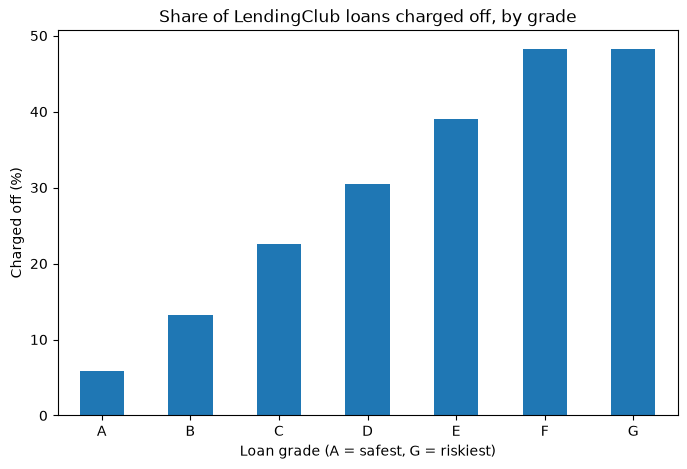

In [28]:
ax = (rate_by_grade["mean"] * 100).plot(kind="bar", figsize=(8, 5))
ax.set_title("Share of LendingClub loans charged off, by grade")
ax.set_xlabel("Loan grade (A = safest, G = riskiest)")
ax.set_ylabel("Charged off (%)")
ax.tick_params(axis="x", rotation=0)

Finding: The share of charged off loans increased steadily with increasing risk grade from about 6% for grade A to about 48% for groups F and G. Grade G has only 446 loans, so its rate is less reliable than others.

## **Second Problem: Default rate by purpose**

In [ ]:
rate_by_purpose = (closed.groupby("purpose")["default"]
                   .agg(["count", "mean"])
                   .sort_values("mean", ascending=False))
rate_by_purpose